# Generalization

### KNN

In [7]:
import seaborn as sns
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import plot_tree, DecisionTreeClassifier
import warnings
warnings.filterwarnings('ignore')

In [8]:
# import dataset
bankloan = pd.read_csv('Dataset/bankloan.csv')
bankloan

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1
1,27,1,10,6,31,17.3,1.362202,4.000798,0
2,40,1,15,14,55,5.5,0.856075,2.168925,0
3,41,1,15,14,120,2.9,2.658720,0.821280,0
4,24,2,2,0,28,17.3,1.787436,3.056564,1
...,...,...,...,...,...,...,...,...,...
695,36,2,6,15,27,4.6,0.262062,0.979938,1
696,29,2,6,4,21,11.5,0.369495,2.045505,0
697,33,1,15,3,32,7.6,0.491264,1.940736,0
698,45,1,19,22,77,8.4,2.302608,4.165392,0


In [9]:
bankloan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       700 non-null    int64  
 1   ed        700 non-null    int64  
 2   employ    700 non-null    int64  
 3   address   700 non-null    int64  
 4   income    700 non-null    int64  
 5   debtinc   700 non-null    float64
 6   creddebt  700 non-null    float64
 7   othdebt   700 non-null    float64
 8   default   700 non-null    int64  
dtypes: float64(3), int64(6)
memory usage: 49.3 KB


In [10]:
# dataset
X = bankloan[['employ','debtinc','creddebt','othdebt']]
y = bankloan[['default']]
display(X,y)

,employ,debtinc,creddebt,othdebt
0,17,9.3,11.359392,5.008608
1,10,17.3,1.362202,4.000798
2,15,5.5,0.856075,2.168925
3,15,2.9,2.658720,0.821280
4,2,17.3,1.787436,3.056564
...,...,...,...,...
695,6,4.6,0.262062,0.979938
696,6,11.5,0.369495,2.045505
697,15,7.6,0.491264,1.940736
698,19,8.4,2.302608,4.165392


,default
0,1
1,0
2,0
3,0
4,1
...,...
695,1
696,0
697,0
698,0


In [11]:
# splitting

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.2,
    random_state=2020
)

In [12]:
# standardization process
scaler = MinMaxScaler()
scaler.fit(X_train) # preprocessing
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
# Iterate k
k = np.arange(1,100,2)
training_accuracies = []
testing_accuracies = []
score = 0

for i in k:
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train_scaled,y_train)

    y_predict_train = knn.predict(X_train_scaled)
    training_accuracies.append(accuracy_score(y_train,y_predict_train))

    y_predict_test = knn.predict(X_test_scaled)
    acc_score = accuracy_score(y_test,y_predict_test)
    testing_accuracies.append(acc_score)

    if score < acc_score:
        score = acc_score
        best_k = i

In [14]:
# create dataFrame
# display (k,training_accuracies,testing_accuracies)
df_k = pd.DataFrame({
    'k':k,
    'training_accuracies': training_accuracies,
    'testing_accuracies': testing_accuracies

}
)

df_melted = pd.melt(df_k,
                    id_vars= ['k'],
                    value_vars= ['training_accuracies', 'testing_accuracies'],
                    value_name= 'value',
                    var_name='attribute'
                    )

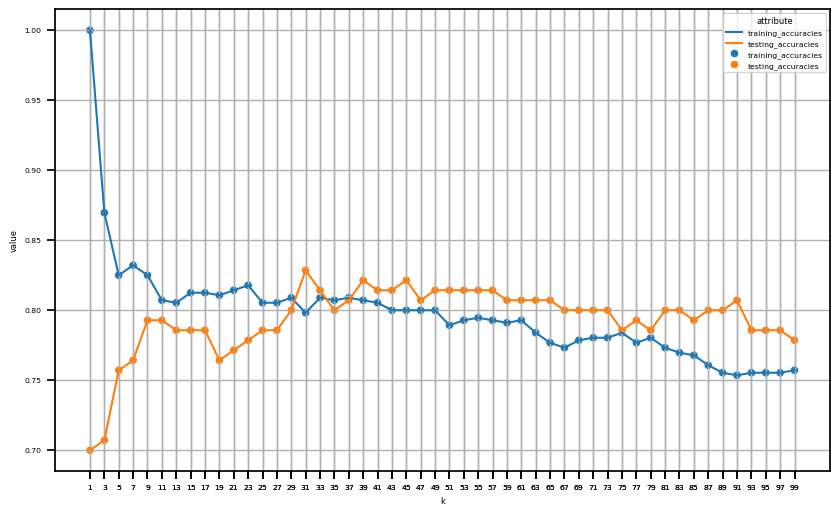

In [18]:
# plot
plt.figure(figsize=(10,6))
sns.set_context('notebook',font_scale=0.5)
ax = sns.lineplot(data=df_melted,x='k',y='value',hue='attribute')
sns.scatterplot(data=df_melted,x='k',y='value',hue='attribute')
ax.set_xticks(df_melted['k'])
plt.grid()

In [19]:
print('best k: ',best_k)
print('accuracy: ',score)

best k:  31
accuracy:  0.8285714285714286


# Summary
1. The best factor k for this case is 31 with 82.85% accuracy.
2. for k = 1, KNN method achieve 100% validations, means it is a very good model for data train, but bad for data test (70% accuracy)
3. for k below 31, the ML method tend to be overfitting and for k above 31, the ML method tend to be underfitting

accuracy used for the test and validation used for the train

### D3

In [21]:
depths = np.arange(1,25)
training_accuracies = []
testing_accuracies = []
score = 0

for i in depths:
    tree = DecisionTreeClassifier(
        criterion='entropy',# entropy, gini
        max_depth= i
        # min_samples_leaf=
        # min_samples_split=
    )
    tree.fit(X_train,y_train)

    y_predict_train = tree.predict(X_train)
    training_accuracies.append(accuracy_score(y_train,y_predict_train))

    y_predict_test = tree.predict(X_test)
    acc_score = accuracy_score(y_test, y_predict_test)
    testing_accuracies.append(acc_score)

    if score < acc_score:
        best_depth = i
        score = acc_score

In [22]:
display(best_depth,training_accuracies,testing_accuracies)

8

[0.7732142857142857,
 0.7732142857142857,
 0.8053571428571429,
 0.8107142857142857,
 0.8321428571428572,
 0.8446428571428571,
 0.8607142857142858,
 0.8714285714285714,
 0.8821428571428571,
 0.8946428571428572,
 0.9160714285714285,
 0.925,
 0.9375,
 0.9589285714285715,
 0.9732142857142857,
 0.9839285714285714,
 0.9928571428571429,
 0.9946428571428572,
 0.9964285714285714,
 0.9982142857142857,
 0.9982142857142857,
 1.0,
 1.0,
 1.0]

[0.7142857142857143,
 0.7142857142857143,
 0.7785714285714286,
 0.7785714285714286,
 0.7785714285714286,
 0.7642857142857142,
 0.7714285714285715,
 0.7857142857142857,
 0.75,
 0.7571428571428571,
 0.7214285714285714,
 0.7428571428571429,
 0.7071428571428572,
 0.7,
 0.6714285714285714,
 0.6857142857142857,
 0.6928571428571428,
 0.6928571428571428,
 0.6785714285714286,
 0.6857142857142857,
 0.7142857142857143,
 0.6928571428571428,
 0.7,
 0.6928571428571428]

In [23]:
df_d = pd.DataFrame({
    'depths' : depths,
    'training_accuracies' : training_accuracies,
    'testing_accuracies' : testing_accuracies
})

df_melted = pd.melt(df_d,
                    id_vars=['depths'],
                    value_vars=['training_accuracies', 'testing_accuracies'],
                    value_name='value',
                    var_name='attribute')
df_melted

,depths,attribute,value
0,1,training_accuracies,0.773214
1,2,training_accuracies,0.773214
2,3,training_accuracies,0.805357
3,4,training_accuracies,0.810714
4,5,training_accuracies,0.832143
5,6,training_accuracies,0.844643
6,7,training_accuracies,0.860714
7,8,training_accuracies,0.871429
8,9,training_accuracies,0.882143
9,10,training_accuracies,0.894643


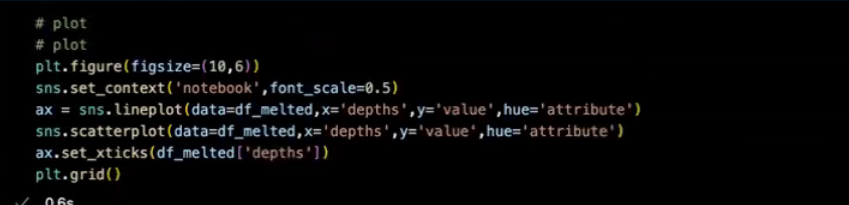

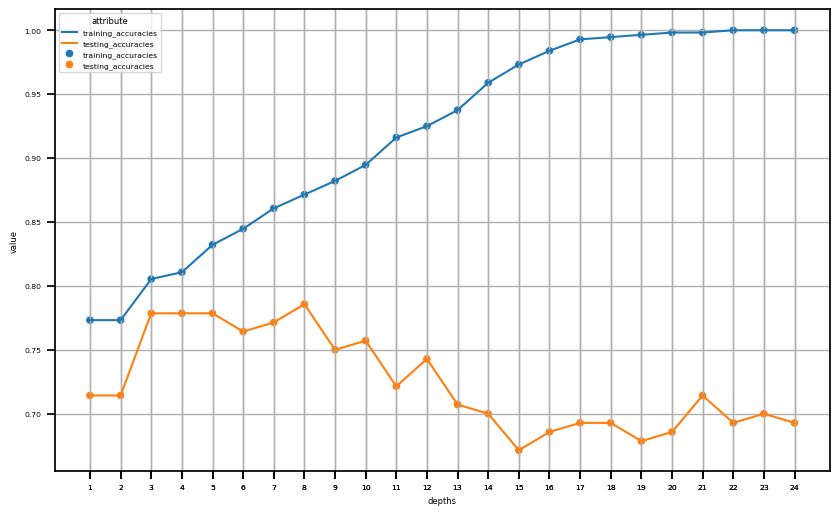

In [24]:
# plot
plt.figure(figsize=(10,6))
sns.set_context('notebook',font_scale=0.5)
ax = sns.lineplot(data=df_melted,x='depths',y='value',hue='attribute')
sns.scatterplot(data=df_melted,x='depths',y='value',hue='attribute')
ax.set_xticks(df_melted['depths'])
plt.grid()

In [25]:
# show the best depth
print('best maximum depth,', best_depth)
print('accuracy:', score)

best maximum depth, 8
accuracy: 0.7857142857142857


# Summary
1. The best depth factor for this case is 8 with 78.57% accuracy.
2. The deeper tree depth, the ML method tend to overfit.
3. when the depth is 24, we got 100% validations, but 70% accuracy. this is the proof of overfit